# 從 nanoGPT 到 Llama 風格：每一個改動到底換到了什麼？

**Sell Anything 的第三本筆記本。** 你在 Karpathy 課程寫過 nanoGPT。
我們的買家模型（`sellanything_ml/llm/model.py`）是 Llama 風格，跟 nanoGPT 有五個地方不同：

| nanoGPT | 我們的模型 | 一句話 |
|---|---|---|
| LayerNorm | **RMSNorm** | 少做一件事（不減平均），結果幾乎一樣 |
| 學出來的位置表 | **RoPE** | 用「旋轉」表示位置，比訓練時更長的句子也能處理 |
| GELU MLP | **SwiGLU** | 多一個「閘門」決定哪些訊號放行 |
| 多頭注意力 | **GQA** | 幾個查詢頭共用一組 K/V，生成時記憶體省一半 |
| 每次生成重算全部 | **KV cache** | 算過的就存起來 |

這本筆記本的原則跟前兩本一樣：**每個改動都要量出一個具體的數字**，不能只說「比較好」。

⚠️ 小模型、短訓練下，loss 的差異常常小於隨機誤差。所以這裡刻意挑**能量得很乾淨的性質**
（速度、記憶體、能不能處理更長的句子），loss 的比較會誠實地標出「這個差距可能只是運氣」。

全部在 CPU 上跑（GPU 讓給正在訓練的模型），大約 5 分鐘。

In [1]:
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, str(Path.cwd().parent))   # 讓筆記本找得到 ml/sellanything_ml（我們自己的模型程式碼）
from sellanything_ml.llm.model import GPT, GPTConfig, RMSNorm, apply_rope, rope_tables

plt.rcParams["font.sans-serif"] = ["Heiti TC", "PingFang HK", "Microsoft JhengHei", "Arial Unicode MS", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
torch.manual_seed(0)
device = torch.device("cpu")
START = time.time()

# 預訓練資料：已經切好 token 的 FineWeb-Edu（uint16，一個 token 2 位元組）
data = np.memmap("../data/processed/pretrain/train.bin", dtype=np.uint16, mode="r")
val = np.memmap("../data/processed/pretrain/val.bin", dtype=np.uint16, mode="r")
VOCAB = 8192
print(f"訓練資料 {len(data):,} 個 token，驗證 {len(val):,} 個")

訓練資料 201,472,723 個 token，驗證 25,171,703 個


## 1. RMSNorm：LayerNorm 少做一件事

LayerNorm 做兩件事：**減掉平均**、**除以標準差**。RMSNorm 只做第二件（除以均方根）。

$$\text{LayerNorm}(x) = \frac{x - \mu}{\sigma}\cdot\gamma + \beta \qquad\qquad \text{RMSNorm}(x) = \frac{x}{\sqrt{\text{mean}(x^2)}}\cdot\gamma$$

先用你在 nanoGPT 講義手算過的 `[1, 2, 3, 4]` 驗算：

In [2]:
x = torch.tensor([[1.0, 2.0, 3.0, 4.0]])
ln = nn.LayerNorm(4, elementwise_affine=False)
rms = RMSNorm(4)
print("LayerNorm:", ln(x).numpy().round(4))
print("RMSNorm:  ", rms(x).detach().numpy().round(4))
print("均方根 =", math.sqrt((1 + 4 + 9 + 16) / 4))

LayerNorm: [[-1.3416 -0.4472  0.4472  1.3416]]
RMSNorm:   [[0.3651 0.7303 1.0954 1.4606]]
均方根 = 2.7386127875258306


RMSNorm 的結果不是平均 0，但每個數字都被縮到「大小約 1」。
**為什麼可以省掉減平均？** Llama、Gemma 這些模型的經驗是：縮放才是穩定訓練的關鍵，置中幾乎沒差。
省下的是計算：

In [3]:
big = torch.randn(64, 512, 384)
layers = [("LayerNorm（內建）", nn.LayerNorm(384)),
          ("RMSNorm（我們手寫）", RMSNorm(384)),
          ("RMSNorm（PyTorch 內建）", nn.RMSNorm(384))]
print("手寫版跟內建版算出來一樣嗎：", torch.allclose(layers[1][1](big), layers[2][1](big), atol=1e-5))
for name, layer in layers:
    layer(big)                                   # 暖身
    t = time.perf_counter()
    for _ in range(20):
        layer(big)
    ms = (time.perf_counter() - t) / 20 * 1000
    params = sum(p.numel() for p in layer.parameters())
    print(f"{name:<20} {ms:6.2f} ms / 次，參數 {params}")

手寫版跟內建版算出來一樣嗎： True


LayerNorm（內建）          3.55 ms / 次，參數 768


RMSNorm（我們手寫）          8.96 ms / 次，參數 384


RMSNorm（PyTorch 內建）    8.08 ms / 次，參數 384


**結果跟直覺相反：在這台電腦的 CPU 上，RMSNorm 比 LayerNorm 慢**（約 8–9 ms 對 3.5 ms；計時每次跑會差一點，兩次執行的倍數是 2.3–2.9 倍）。
連 PyTorch 內建的 `nn.RMSNorm` 也一樣慢，所以不是我們手寫得差。

為什麼？「少做一件事」是**算術**上的節省，但速度取決於**實作**：LayerNorm 在 PyTorch 裡有一個高度最佳化、一次做完的核心程式，
RMSNorm 在這裡是幾個小運算接起來（平方、平均、開根號、相乘），每一步都要把整個張量讀寫一次。

那為什麼 Llama 還用它？因為在 GPU 上大家會寫成一次做完的版本，那時候少一個減法、少一個參數才真的省得到；
而且實驗上它訓練得跟 LayerNorm 一樣穩。📌 **這一格要帶走的一句：「理論上比較快」要在你自己的硬體上量過才算數。**
（GPU 上的速度這本筆記本沒有量：GPU 正在訓練買家模型。）

## 2. RoPE：用旋轉表示位置

nanoGPT 的位置嵌入是一張表：第 0 格、第 1 格……第 `block_size-1` 格，每格學一個向量。
**問題：表只有 `block_size` 列。** 你在講義 §18 觸發過 `IndexError`：句子比訓練時長，就查不到。

RoPE 不查表，而是把 q 和 k 的每一對數字**依照位置旋轉一個角度**。兩個 token 的注意力分數
只跟它們的「相對距離」有關。先驗證這件事：

In [4]:
cos, sin = rope_tables(8, 64, 10000.0)
q, k = torch.randn(8), torch.randn(8)
qs = apply_rope(q.expand(1, 1, 64, 8), cos, sin)[0, 0]
ks = apply_rope(k.expand(1, 1, 64, 8), cos, sin)[0, 0]
for p in (0, 10, 40):
    print(f"q 在第 {p:2d} 格、k 在第 {p + 3:2d} 格：分數 {(qs[p] @ ks[p + 3]).item():+.5f}")
print("向量長度沒變：", torch.allclose(qs.norm(dim=-1), q.norm().expand(64), atol=1e-5))

q 在第  0 格、k 在第  3 格：分數 -1.35471
q 在第 10 格、k 在第 13 格：分數 -1.35471
q 在第 40 格、k 在第 43 格：分數 -1.35471
向量長度沒變： True


三個位置的分數一樣：**只看距離（3），不看絕對位置**。

### 實驗：訓練 128 長，測 256 長

訓練兩個一模一樣大小的小模型，只差位置的表示法：
- **A**：nanoGPT 式，學一張位置表
- **B**：RoPE

都用長度 128 訓練，再拿長度 256 的文字測。

In [5]:
class LearnedPosGPT(nn.Module):
    '''跟我們的 GPT 一樣，只是 RoPE 換成 nanoGPT 式的位置表（拿掉旋轉）。'''

    def __init__(self, cfg):
        super().__init__()
        self.gpt = GPT(cfg)
        self.pos = nn.Embedding(cfg.max_seq_len, cfg.d_model)
        # ⚠️ 一定要跟 token 嵌入用同樣的初始化（std 0.02）。nn.Embedding 的預設是 std 1.0，
        # 比 token 嵌入大 50 倍，位置雜訊會把「這是哪個字」整個蓋掉（下面有實際踩到的數字）。
        nn.init.normal_(self.pos.weight, std=0.02)
        # 把旋轉關掉：cos=1、sin=0 就是「不轉」
        self.gpt.rope_cos.fill_(1.0)
        self.gpt.rope_sin.fill_(0.0)
        self.gpt.embed.register_forward_hook(lambda m, i, out: out + self.pos(torch.arange(out.size(1))))

    def forward(self, idx, targets=None):
        return self.gpt(idx, targets)


def batches(source, block, batch, rng):
    starts = rng.integers(0, len(source) - block - 1, batch)
    chunk = torch.from_numpy(np.stack([source[s:s + block + 1] for s in starts]).astype(np.int64))
    return chunk[:, :-1], chunk[:, 1:]


def train(model, steps=500, block=128, batch=16, lr=2e-3, seed=0):
    '''同樣的種子 → 同樣的批次順序，兩個模型看到完全一樣的資料。'''
    rng = np.random.default_rng(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    losses = []
    for step in range(steps):
        x, y = batches(data, block, batch, rng)
        loss = model(x, y)[1]
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


@torch.no_grad()
def eval_loss(model, block, n=40):
    rng = np.random.default_rng(123)
    model.eval()
    out = np.mean([model(*batches(val, block, 8, rng))[1].item() for _ in range(n)])
    model.train()
    return out


tiny = dict(vocab_size=VOCAB, d_model=128, n_layers=4, n_heads=4, n_kv_heads=4)
torch.manual_seed(0)
model_a = LearnedPosGPT(GPTConfig(max_seq_len=128, **tiny))
torch.manual_seed(0)
model_b = GPT(GPTConfig(max_seq_len=256, **tiny))   # RoPE 的表算到 256，但只用 128 訓練

t = time.time()
loss_a = train(model_a)
loss_b = train(model_b)
print(f"兩個各訓練 500 步，共 {time.time() - t:.0f} 秒")
print(f"長度 128 的驗證 loss：位置表 {eval_loss(model_a, 128):.3f}，RoPE {eval_loss(model_b, 128):.3f}")

兩個各訓練 500 步，共 94 秒


長度 128 的驗證 loss：位置表 6.067，RoPE 5.755


In [6]:
print("長度 256 的驗證 loss：")
print(f"  RoPE：{eval_loss(model_b, 256):.3f}")
try:
    eval_loss(model_a, 256)
except IndexError as e:
    print(f"  位置表：IndexError（{e}）——第 128 格以後根本查不到")

長度 256 的驗證 loss：


  RoPE：5.820
  位置表：IndexError（index out of range in self）——第 128 格以後根本查不到


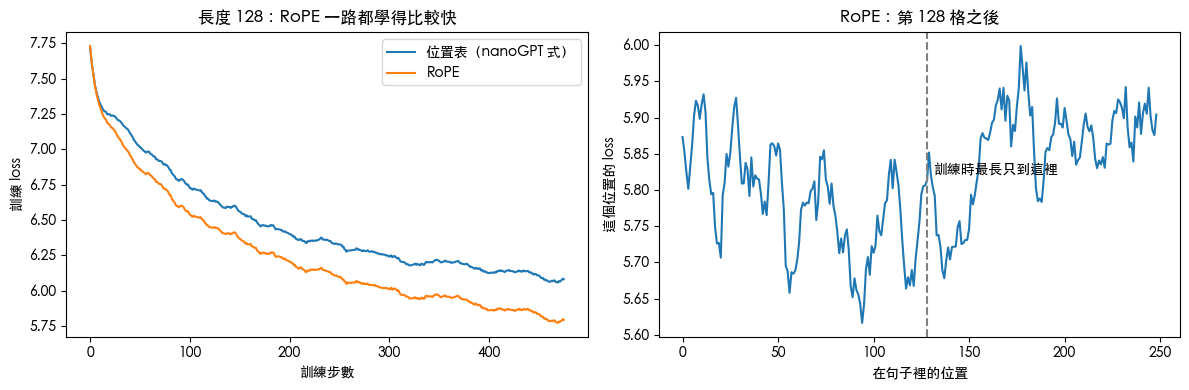

RoPE 位置 0–127 平均 loss 5.785，位置 128–255 平均 5.855


In [7]:
# 圖 1：兩個模型的訓練曲線（每 25 步取平均，比較好看）
def smooth(v, k=25):
    return np.convolve(v, np.ones(k) / k, mode="valid")

# 圖 2：RoPE 模型在「每一個位置」的 loss，看第 128 格之後有沒有崩掉
@torch.no_grad()
def loss_by_position(model, block, n=40):
    rng = np.random.default_rng(123)
    model.eval()
    total = torch.zeros(block)
    for _ in range(n):
        x, y = batches(val, block, 8, rng)
        logits, _ = model(x)
        total += F.cross_entropy(logits.transpose(1, 2), y, reduction="none").mean(0)
    model.train()
    return (total / n).numpy()

pos_loss = loss_by_position(model_b, 256)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(smooth(loss_a), label="位置表（nanoGPT 式）")
ax1.plot(smooth(loss_b), label="RoPE")
ax1.set(xlabel="訓練步數", ylabel="訓練 loss", title="長度 128：RoPE 一路都學得比較快")
ax1.legend()
ax2.plot(smooth(pos_loss, 8))
ax2.axvline(128, color="gray", ls="--")
ax2.text(131, ax2.get_ylim()[1] * 0.97, "訓練時最長只到這裡", va="top")
ax2.set(xlabel="在句子裡的位置", ylabel="這個位置的 loss", title="RoPE：第 128 格之後")
plt.tight_layout()
plt.show()
print(f"RoPE 位置 0–127 平均 loss {pos_loss[:128].mean():.3f}，位置 128–255 平均 {pos_loss[128:].mean():.3f}")

三個數字：

| | 長度 128 驗證 loss | 長度 256 驗證 loss |
|---|---|---|
| 位置表（nanoGPT 式） | 6.067 | ❌ `IndexError`，根本跑不了 |
| RoPE | **5.755** | **5.820** |

- **能不能處理比訓練時更長的句子**：這是 RoPE 最乾淨的優勢。位置表只有 128 列，第 129 格查不到；RoPE 的角度用公式算，多長都算得出來。
- **右圖**：RoPE 在第 128 格之後 loss 只高一點（5.785 → 5.855），沒有崩掉。但也不是「完全一樣好」——它沒在那些距離上練習過。
- **長度 128 上 RoPE 也學得比較快**（左圖兩條線一路分開，最後差 0.31）。⚠️ 但這裡兩個模型各只訓練一次，這個差距沒有用多個種子確認。

⚠️ **這一節我第一次跑錯了，值得記住**：第一版位置表模型的 loss 是 **7.215**，差得離譜。
查出來是 `nn.Embedding` 預設用 **std 1.0** 初始化，而 token 嵌入用的是 **0.02**——位置雜訊比字的訊號大 50 倍，把「這是哪個字」蓋掉了。
改成同樣的 0.02 之後才是上表的 6.067。📌 **比較兩種架構時，除了架構以外的東西（初始化、資料、步數、種子）都要一樣，否則比的是別的東西。**

## 3. SwiGLU：多一個閘門

nanoGPT 的 MLP：`d → 4d → GELU → d`，兩個矩陣。

SwiGLU：兩條路一起算，一條過 SiLU 當「閘門」，另一條是內容，**逐元素相乘**後再投影回去。三個矩陣：

```
gate = silu(x @ W_gate)      # 每個位置要放行多少（0 附近 = 關、大 = 開）
up   = x @ W_up              # 內容
out  = (gate * up) @ W_down
```

三個矩陣比兩個多，所以中間寬度從 4d 縮成約 8/3·d，**總參數量保持一樣**：

In [8]:
d = 384
gelu_mlp = 2 * d * (4 * d)
ffn = GPTConfig(d_model=d).ffn_dim
swiglu = 3 * d * ffn
print(f"GELU MLP（4d={4 * d}）：{gelu_mlp:,} 參數")
print(f"SwiGLU（{ffn}，約 8/3·d）：{swiglu:,} 參數，差 {abs(swiglu - gelu_mlp) / gelu_mlp:.1%}")

GELU MLP（4d=1536）：1,179,648 參數
SwiGLU（1024，約 8/3·d）：1,179,648 參數，差 0.0%


In [9]:
class GeluMLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc = nn.Linear(cfg.d_model, 4 * cfg.d_model, bias=False)
        self.proj = nn.Linear(4 * cfg.d_model, cfg.d_model, bias=False)

    def forward(self, x):
        return self.proj(F.gelu(self.fc(x)))


def with_gelu(cfg):
    m = GPT(cfg)
    for block in m.blocks:
        block.mlp = GeluMLP(cfg)
        # 換上去的新層要用跟 SwiGLU 一樣的初始化，否則比的是「初始化」不是「架構」
        nn.init.normal_(block.mlp.fc.weight, std=0.02)
        nn.init.normal_(block.mlp.proj.weight, std=0.02 / math.sqrt(2 * cfg.n_layers))
    return m


results = {}
for name, make in [("GELU MLP", with_gelu), ("SwiGLU", GPT)]:
    for seed in (0, 1, 2):
        torch.manual_seed(seed)
        m = make(GPTConfig(max_seq_len=128, **tiny))
        train(m, steps=400, seed=seed)
        results.setdefault(name, []).append(eval_loss(m, 128))
for name, v in results.items():
    print(f"{name:>8}: 三個種子 {np.round(v, 3)}，平均 {np.mean(v):.3f}，標準差 {np.std(v):.3f}")

GELU MLP: 三個種子 [6.046 6.126 6.057]，平均 6.076，標準差 0.036
  SwiGLU: 三個種子 [5.885 5.817 5.848]，平均 5.850，標準差 0.028


SwiGLU 比 GELU 低 **0.23**（5.850 對 6.076），而三個種子各自的標準差只有 0.03 左右——差距是誤差的六倍以上，**不是運氣**。
參數量完全一樣（1,179,648），所以贏的是「閘門」這個結構，不是多給了參數。

⚠️ **這一節第一次跑出相反的結論**：SwiGLU 5.850、GELU **5.756**，看起來 GELU 比較好。
原因跟上一節一樣是初始化：換上去的 GELU 層用了 PyTorch 預設的初始化，比模型其他地方大好幾倍，殘差輸出也沒縮小。
統一初始化後，GELU 從 5.756 變成 6.076，結論翻過來。
📌 **一個「意外的贏家」常常是實驗不公平，不是新發現。**

## 4. GQA：查詢頭多、K/V 頭少

多頭注意力（MHA）每個頭都有自己的 Q、K、V。**GQA** 讓幾個查詢頭共用同一組 K、V。

為什麼？生成文字時，每個已經看過的 token 的 K、V 都要存起來（下一節的 KV cache）。
K/V 頭少一半，**這份快取就小一半**。我們的 mini 模型是 6 個查詢頭、3 個 K/V 頭：

In [10]:
def kv_cache_bytes(cfg, seq_len, bytes_per=2):     # bfloat16 = 2 位元組
    return 2 * cfg.n_layers * cfg.n_kv_heads * cfg.head_dim * seq_len * bytes_per   # 2 = K 和 V

mini = dict(vocab_size=VOCAB, d_model=384, n_layers=6, n_heads=6)
for kv in (6, 3, 1):
    cfg = GPTConfig(n_kv_heads=kv, **mini)
    params = GPT(cfg).num_params()
    print(f"K/V 頭 {kv}：參數 {params:,}，1,024 個 token 的快取 {kv_cache_bytes(cfg, 1024) / 1024:.0f} KB")

K/V 頭 6：參數 13,767,552，1,024 個 token 的快取 9216 KB


K/V 頭 3：參數 12,882,816，1,024 個 token 的快取 4608 KB


K/V 頭 1：參數 12,292,992，1,024 個 token 的快取 1536 KB


- K/V 頭從 6 降到 3（我們的 mini 模型）：1,024 個 token 的快取從 **9,216 KB → 4,608 KB，剛好一半**；參數少了 884,736 個（6.4%）。
- 降到 1 個（叫 MQA）：快取剩 1/6，但所有查詢頭只能共用同一組 K/V，通常會掉品質。GQA 是兩者中間的折衷。

快取大小可以自己驗算：`2（K 和 V）× 6 層 × 3 頭 × 64 維 × 1,024 個 token × 2 位元組 = 4,718,592 位元組 = 4,608 KB`。
這個模型很小，省 4.5 MB 不痛不癢；但 Llama 等級的模型上下文是幾萬個 token，快取會到好幾 GB，這時候省一半就是能不能跑的差別。

## 5. KV cache：算過的就存起來

你在 nanoGPT 講義 §8b 看過：`generate` 每生一個字，**整段重新算一次**，
序列長 100 時算 100 個位置、只用最後一個。

KV cache：每一層把算過的 K、V 存起來，下一步只算**新的那一個 token**。
我們的 `GPT.generate` 用的就是它；這裡跟「每次重算」比速度，並確認**結果完全一樣**：

In [11]:
torch.manual_seed(0)
m = GPT(GPTConfig(max_seq_len=512, n_kv_heads=3, **mini)).eval()   # 跟遊戲用的 mini 一樣：6 頭、3 組 K/V
prompt = torch.randint(0, VOCAB, (1, 64))
n_new = 128

t = time.perf_counter()
with_cache = m.generate(prompt, n_new, temperature=0)
t_cache = time.perf_counter() - t

t = time.perf_counter()
seq = prompt
with torch.no_grad():
    for _ in range(n_new):
        logits, _ = m(seq)
        seq = torch.cat([seq, logits[:, -1].argmax(-1, keepdim=True)], dim=1)
t_full = time.perf_counter() - t

print(f"有 KV cache：{t_cache:.2f} 秒；每次重算：{t_full:.2f} 秒；快 {t_full / t_cache:.1f} 倍")
print("產生的 token 完全一樣：", torch.equal(with_cache, seq))

有 KV cache：0.25 秒；每次重算：1.21 秒；快 4.8 倍
產生的 token 完全一樣： True


- **快 4–5 倍**（兩次執行分別量到 4.2 倍和 4.8 倍），而且產生的 128 個 token **一個都不差**——它只是不重算，沒有改變任何數學。
- 為什麼不是快 100 倍？每次重算時序列只有 64–192 個 token，這麼短的序列重算本身就不貴；序列越長，省的越多。
- 我們遊戲裡每句買家台詞在 CPU 上只要約 0.04 秒，KV cache 是原因之一。

## 總結

| 改動 | 量到的 | 誠實的附註 |
|---|---|---|
| RMSNorm | 算出來跟手算一樣；在這台 CPU 上**比 LayerNorm 慢 2–3 倍** | 省的是算術，速度看實作；GPU 沒量 |
| RoPE | 訓練 128、測 256：RoPE 5.820，位置表**直接 IndexError**；128 上 5.755 對 6.067 | 128 上的差距只跑了一個種子 |
| SwiGLU | 參數一樣，loss 5.850 對 6.076，差距是誤差的 6 倍以上 | 三個種子、各 400 步的小模型 |
| GQA | K/V 頭 6 → 3：快取剛好減半（9,216 → 4,608 KB） | 品質影響這裡沒有量 |
| KV cache | 快 4–5 倍、結果逐字相同 | 序列越長省越多 |

這一本最大的教訓不是哪個架構贏，而是 **兩次「意外結論」都是初始化不公平造成的**。改架構做比較時，先確定只有那一個東西不一樣。

In [12]:
print(f"整本跑了 {(time.time() - START) / 60:.1f} 分鐘")

整本跑了 5.4 分鐘
